# ShifAI — Acanthosis nigricans skin-photo model (v2: Fitzpatrick17k + SCIN)
**Screening hint only — never a diagnosis.** The model estimates whether a skin photo (mainly the neck) shows signs consistent with acanthosis nigricans (dark, thick, velvety patches). A positive result only means *"consider talking to a doctor"*.

**Colab :** `Exécution → Modifier le type d'exécution → GPU (T4)`, puis `Exécution → Tout exécuter`.  
**Kaggle :** panneau de droite → *Accelerator* : **GPU T4 x2** ou **P100**, *Internet* : **On** (nécessite un compte vérifié par téléphone), puis **Run All**.  
À la fin, un fichier `shifai_an_outputs.zip` se télécharge (tableau de résultats, exemples, Grad-CAM, `model.tflite`, sources/licences, limites).  
Ensuite : `Fichier → Télécharger → .ipynb` pour envoyer le notebook **avec les résultats affichés**.

**Règles respectées dans ce notebook :** split 70/15/15 avant l'entraînement, seuil choisi sur la validation, test utilisé **une seule fois** à la fin, chiffres tronqués (jamais arrondis vers le haut) avec les effectifs bruts.

## 1. Installation et configuration

In [1]:
!pip -q install imagehash

In [2]:
import os, io, json, math, random, hashlib, zipfile, warnings
import numpy as np, pandas as pd, requests
from PIL import Image
import imagehash
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

BACKBONE  = "mobilenetv3"   # "mobilenetv3" (MobileNetV3-Small, plus léger) ou "efficientnet" (EfficientNet-B0)
IMG       = 224
NEG_RATIO = 1               # 1 image "autre" pour 1 image AN -> classes équilibrées
BATCH     = 16
N_UNFREEZE = 30             # nombre de couches du backbone dégelées au fine-tuning

ON_KAGGLE = os.path.exists("/kaggle/working")
ROOT = "/kaggle/working" if ON_KAGGLE else "/content"
WORK, OUT = f"{ROOT}/an_work", f"{ROOT}/outputs"
IMG_DIR = f"{WORK}/images"
os.makedirs(IMG_DIR, exist_ok=True); os.makedirs(OUT, exist_ok=True)
print("Platform:", "Kaggle" if ON_KAGGLE else "Colab", "| TF", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1795368764.436783      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795368776.407116      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Platform: Kaggle | TF 2.21.0 | Keras 3.13.2 | GPU: []


E0000 00:00:1795368780.202025      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 2. Sources et licences
Chaque dataset utilisé doit être listé ici **avec sa licence**. N'ajoute rien dont la licence interdit cet usage (par exemple, ne pas récupérer les images DermNet, Mayo Clinic ou d'atlas protégés par le droit d'auteur).

In [3]:
SOURCES = [
    {"dataset": "Fitzpatrick17k",
     "url": "https://github.com/mattgroh/fitzpatrick17k",
     "licence": "CC BY-NC-SA 3.0 (attribution, non-commercial, share-alike). Images originally from DermaAmin and Atlas Dermatologico.",
     "used_for": "acanthosis nigricans (positive class) + other skin conditions (negative class)",
     "citation": "Groh et al., 'Evaluating Deep Neural Networks Trained on Clinical Images in Dermatology with the Fitzpatrick 17k Dataset', CVPR Workshops 2021"},
    # Ajoute ici chaque dataset Kaggle / Roboflow utilisé, par ex. :
    # {"dataset": "...", "url": "...", "licence": "CC BY 4.0", "used_for": "...", "citation": "..."},
]

## 3. Données — Fitzpatrick17k

In [4]:
CSV_URL = "https://raw.githubusercontent.com/mattgroh/fitzpatrick17k/main/fitzpatrick17k.csv"
df = pd.read_csv(CSV_URL)
df = df[df.url.notna()].drop_duplicates("md5hash").copy()
df["y"] = (df.label == "acanthosis nigricans").astype(int)
pos, neg_pool = df[df.y == 1], df[df.y == 0]
print("AN rows in CSV:", len(pos))
print("AN by Fitzpatrick type:\n", pos.fitzpatrick_scale.value_counts().sort_index())

# Candidats négatifs : autres maladies de peau, avec la MÊME répartition de teintes que les positifs
# (pour que le modèle n'apprenne pas la couleur de peau comme raccourci). x3 car des liens sont morts.
parts = []
for fs, n in pos.fitzpatrick_scale.value_counts().items():
    pool = neg_pool[neg_pool.fitzpatrick_scale == fs]
    parts.append(pool.sample(min(len(pool), n * NEG_RATIO * 3), random_state=SEED))
to_dl = pd.concat([pos, pd.concat(parts)]).reset_index(drop=True)
print("Images to try downloading:", len(to_dl))

AN rows in CSV: 92
AN by Fitzpatrick type:
 fitzpatrick_scale
-1     2
 1     9
 2    11
 3    23
 4    19
 5    17
 6    11
Name: count, dtype: int64
Images to try downloading: 368


In [5]:
HEADERS = {"User-Agent": "Mozilla/5.0 (student research project)"}

def fetch(row):
    path = f"{IMG_DIR}/{row.md5hash}.jpg"
    if os.path.exists(path):
        return row.md5hash, path, "cached"
    try:
        r = requests.get(row.url, headers=HEADERS, timeout=20)
        if r.status_code != 200:
            return row.md5hash, None, f"http {r.status_code}"
        im = Image.open(io.BytesIO(r.content)).convert("RGB")
        im.thumbnail((512, 512)); im.save(path, "JPEG", quality=92)
        return row.md5hash, path, "ok"
    except Exception as e:
        return row.md5hash, None, type(e).__name__

with ThreadPoolExecutor(16) as ex:
    res = list(ex.map(fetch, list(to_dl.itertuples())))
st = pd.DataFrame(res, columns=["md5hash", "path", "status"])
to_dl = to_dl.merge(st, on="md5hash")
print(pd.crosstab(to_dl.status, to_dl.y.map({1: "AN", 0: "other"})))
data = to_dl[to_dl.path.notna()].copy()
data["source"] = "Fitzpatrick17k"
print("\nDownloaded OK -> AN:", (data.y == 1).sum(), "| other:", (data.y == 0).sum())

y         AN  other
status             
http 404  70    197
ok        22     79

Downloaded OK -> AN: 22 | other: 79


### 3b. (Optionnel) Données supplémentaires Kaggle / Roboflow
Si tu trouves un dataset « acanthosis nigricans » (ou de peau normale) **dont la licence autorise l'usage** :
1. Ajoute-le dans `SOURCES` (cellule 2) avec son URL et sa licence.
2. Mets les images dans `extra/acanthosis/` (positifs) et `extra/other/` (sous `/content` sur Colab, `/kaggle/working` sur Kaggle) (autres conditions ou peau normale).
3. Relance à partir d'ici. Sans dossier `extra`, cette cellule ne fait rien.

Ces images n'ont pas de score Fitzpatrick : elles comptent dans le groupe « unknown ».

In [6]:
EXTRA = f"{ROOT}/extra"
rows = []
for sub, y in [("acanthosis", 1), ("other", 0)]:
    d = f"{EXTRA}/{sub}"
    if not os.path.isdir(d):
        continue
    for f in sorted(os.listdir(d)):
        try:
            raw = open(f"{d}/{f}", "rb").read()
            im = Image.open(io.BytesIO(raw)).convert("RGB"); im.thumbnail((512, 512))
            h = "extra_" + hashlib.md5(raw).hexdigest()
            p = f"{IMG_DIR}/{h}.jpg"; im.save(p, "JPEG", quality=92)
            rows.append({"md5hash": h, "y": y, "fitzpatrick_scale": -1, "label": sub, "path": p, "source": "extra"})
        except Exception as e:
            print("skip", f, e)
if rows:
    assert len(SOURCES) > 1, "Ajoute la source et la licence des images 'extra' dans SOURCES avant de continuer."
    data = pd.concat([data, pd.DataFrame(rows)], ignore_index=True)
    print("Extra images added:", len(rows))
pd.DataFrame(SOURCES).to_csv(f"{OUT}/dataset_sources.csv", index=False)
print(data.y.value_counts().rename({1: "AN", 0: "other"}))

y
other    79
AN       22
Name: count, dtype: int64


### 3c. Google SCIN (photos prises au téléphone)
**SCIN** (Skin Condition Image Network, Google) : photos de peau prises par des personnes avec leur téléphone, avec labels de dermatologues et teinte de peau.  
Licence : *SCIN Data Use License* (partage et adaptation autorisés, attribution obligatoire, **interdiction de tenter de ré-identifier les personnes**).  
La cellule compte d'abord les cas d'acanthosis nigricans. On garde **une seule photo par cas** (pour qu'une même personne ne se retrouve pas dans train et test), et seulement les cas où l'acanthosis nigricans est le label principal (poids ≥ 0,5).

In [7]:
USE_SCIN = True
SCIN_MIN_WEIGHT = 0.5

if USE_SCIN:
    import ast, re
    B = "https://storage.googleapis.com/dx-scin-public-data/"
    cases = pd.read_csv(B + "dataset/scin_cases.csv", dtype={"case_id": str})
    labels = pd.read_csv(B + "dataset/scin_labels.csv", dtype={"case_id": str})
    sc = cases.merge(labels, on="case_id")

    def wdict(s):
        try:
            return ast.literal_eval(s) if isinstance(s, str) else {}
        except Exception:
            return {}
    sc["w"] = sc.weighted_skin_condition_label.map(wdict)
    sc["an_w"] = sc.w.map(lambda d: sum(v for k, v in d.items() if "acanthosis" in k.lower()))

    def fst(r):
        for c in ["dermatologist_fitzpatrick_skin_type_label_1", "fitzpatrick_skin_type"]:
            v = r.get(c)
            m = re.search(r"([1-6])", v) if isinstance(v, str) else None
            if m:
                return int(m.group(1))
        return -1
    sc["fitzpatrick_scale"] = sc.apply(fst, axis=1)
    sc = sc[sc.image_1_path.notna()]

    sc_pos = sc[sc.an_w >= SCIN_MIN_WEIGHT]
    sc_neg_pool = sc[(sc.an_w == 0) & (sc.w.map(len) > 0)]
    print("SCIN cases:", len(sc), "| any AN mention:", int((sc.an_w > 0).sum()),
          "| AN as main label:", len(sc_pos))
    print("SCIN AN by Fitzpatrick type:\n", sc_pos.fitzpatrick_scale.value_counts().sort_index())

    parts = [sc_pos]
    for fs, n in sc_pos.fitzpatrick_scale.value_counts().items():
        pool = sc_neg_pool[sc_neg_pool.fitzpatrick_scale == fs]
        parts.append(pool.sample(min(len(pool), n * NEG_RATIO * 2), random_state=SEED))
    sc_dl = pd.concat(parts)

    def fetch_scin(r):
        path = f"{IMG_DIR}/scin_{r.case_id}.jpg"
        if not os.path.exists(path):
            try:
                resp = requests.get(B + r.image_1_path, timeout=30)
                im = Image.open(io.BytesIO(resp.content)).convert("RGB")
                im.thumbnail((512, 512)); im.save(path, "JPEG", quality=92)
            except Exception:
                return None
        top = max(r.w, key=r.w.get) if r.w else "unknown"
        return {"md5hash": f"scin_{r.case_id}", "y": int(r.an_w >= SCIN_MIN_WEIGHT),
                "fitzpatrick_scale": r.fitzpatrick_scale, "label": top, "path": path,
                "url": B + r.image_1_path, "source": "SCIN"}

    with ThreadPoolExecutor(16) as ex:
        got = [x for x in ex.map(fetch_scin, list(sc_dl.itertuples())) if x]
    if got:
        data = pd.concat([data, pd.DataFrame(got)], ignore_index=True)
        SOURCES.append({"dataset": "SCIN (Skin Condition Image Network), Google Research",
                        "url": "https://github.com/google-research-datasets/scin",
                        "licence": "SCIN Data Use License: share/adapt allowed with attribution; re-identification of individuals prohibited",
                        "used_for": "smartphone photos: AN (main dermatologist label, weight >= 0.5) + other conditions; 1 image per case",
                        "citation": "Ward et al., 'Creating an Empirical Dermatology Dataset Through Crowdsourcing With Web Search Advertisements', JAMA Netw Open 2024"})
        pd.DataFrame(SOURCES).to_csv(f"{OUT}/dataset_sources.csv", index=False)
    print("SCIN images added:", len(got))
    print(pd.crosstab(data.source, data.y.map({1: "AN", 0: "other"})))

SCIN cases: 5033 | any AN mention: 5 | AN as main label: 2
SCIN AN by Fitzpatrick type:
 fitzpatrick_scale
3    1
5    1
Name: count, dtype: int64
SCIN images added: 6
y               AN  other
source                   
Fitzpatrick17k  22     79
SCIN             2      4


## 4. Doublons, équilibrage des classes, split 70/15/15

In [8]:
# Doublons quasi identiques (perceptual hash, distance <= 4) -> on n'en garde qu'un.
# Si deux doublons ont des labels différents, on supprime les deux.
data = data.reset_index(drop=True)
data["phash"] = [imagehash.phash(Image.open(p)) for p in data.path]
ph, ys, drop = list(data.phash), list(data.y), set()
for i in range(len(data)):
    if i in drop:
        continue
    for j in range(i + 1, len(data)):
        if j not in drop and ph[i] - ph[j] <= 4:
            drop.add(j)
            if ys[i] != ys[j]:
                drop.add(i)
print("Near-duplicates removed:", len(drop))
data = data.drop(index=list(drop)).reset_index(drop=True)

# Équilibrage : autant d'"autres" que d'AN, en suivant la répartition des teintes des AN
# (par source, pour que la source -- atlas vs téléphone -- ne devienne pas un raccourci)
balanced = []
for src in data.source.unique():
    P = data[(data.y == 1) & (data.source == src)]
    N = data[(data.y == 0) & (data.source == src)]
    n_neg = min(len(N), len(P) * NEG_RATIO)
    parts = []
    for fs, n in P.fitzpatrick_scale.value_counts().items():
        pool = N[N.fitzpatrick_scale == fs]
        parts.append(pool.sample(min(len(pool), n * NEG_RATIO), random_state=SEED))
    Nb = pd.concat(parts) if parts else N.iloc[:0]
    if len(Nb) < n_neg:
        rest = N.drop(Nb.index)
        Nb = pd.concat([Nb, rest.sample(min(n_neg - len(Nb), len(rest)), random_state=SEED)])
    balanced += [P, Nb]
data = pd.concat(balanced).sample(frac=1, random_state=SEED).reset_index(drop=True)
print(pd.crosstab(data.source, data.y.map({1: "AN", 0: "other"})))

TONE = {1: "I-II", 2: "I-II", 3: "III-IV", 4: "III-IV", 5: "V-VI", 6: "V-VI"}
data["tone"] = data.fitzpatrick_scale.map(lambda s: TONE.get(int(s), "unknown"))
print(pd.crosstab(data.tone, data.y.map({1: "AN", 0: "other"}), margins=True))

Near-duplicates removed: 0
y               AN  other
source                   
Fitzpatrick17k  22     22
SCIN             2      2
y       AN  other  All
tone                  
I-II     1      1    2
III-IV  20     20   40
V-VI     3      3    6
All     24     24   48


In [9]:
# Split PAR IMAGE, AVANT tout entraînement. Stratifié par classe (et par teinte si les effectifs le permettent).
def strat_key(d, min_n):
    k = d.y.astype(str) + "_" + d.tone
    vc = k.value_counts()
    k = k.where(k.map(vc) >= min_n, d.y.astype(str) + "_rare")   # groupes trop petits regroupés
    return k if k.value_counts().min() >= min_n else d.y.astype(str)

train, tmp = train_test_split(data, test_size=0.30, stratify=strat_key(data, 4), random_state=SEED)
val, test = train_test_split(tmp, test_size=0.50, stratify=strat_key(tmp, 2), random_state=SEED)

# Vérification : aucune image (ni quasi-doublon) partagée entre deux splits
for a, b, name in [(train, val, "train/val"), (train, test, "train/test"), (val, test, "val/test")]:
    assert not set(a.md5hash) & set(b.md5hash), f"overlap {name}"
    assert min((x - y for x in a.phash for y in b.phash), default=99) > 4, f"near-duplicate across {name}"
print("No overlap between splits ✔")

split_df = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")])
split_df.drop(columns=["phash"]).to_csv(f"{OUT}/splits.csv", index=False)
print(pd.crosstab([split_df.split, split_df.tone], split_df.y.map({1: "AN", 0: "other"}), margins=True))

No overlap between splits ✔
y             AN  other  All
split tone                  
test  III-IV   4      4    8
train I-II     1      1    2
      III-IV  13     14   27
      V-VI     2      2    4
val   III-IV   3      2    5
      V-VI     1      1    2
All           24     24   48


## 5. Pipeline d'images + augmentation

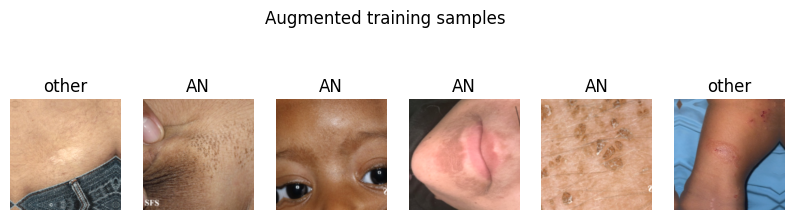

In [10]:
aug = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),                       # rotation
    layers.RandomZoom(0.15),                           # zoom
    layers.RandomBrightness(0.15, value_range=(0, 255)),  # luminosité
], name="augment")

def load(path, y):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    return tf.cast(img, tf.float32), tf.cast(y, tf.float32)   # pixels 0-255, RGB

def make_ds(d, training):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values.astype(str), d.y.values))
    if training:
        ds = ds.shuffle(len(d), seed=SEED)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH)
    if training:
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

ds_tr, ds_va, ds_te = make_ds(train, True), make_ds(val, False), make_ds(test, False)

xb, yb = next(iter(ds_tr))
plt.figure(figsize=(10, 3))
for i in range(min(6, len(yb))):
    plt.subplot(1, 6, i + 1); plt.imshow(np.clip(xb[i].numpy(), 0, 255).astype("uint8"))
    plt.title("AN" if yb[i] == 1 else "other"); plt.axis("off")
plt.suptitle("Augmented training samples"); plt.show()

## 6. Modèle — étape 1 : entraîner seulement la dernière couche

In [11]:
def build(backbone):
    inp = keras.Input((IMG, IMG, 3))   # pixels 0-255 ; la normalisation est incluse dans le backbone
    if backbone == "mobilenetv3":
        base = keras.applications.MobileNetV3Small(include_top=False, weights="imagenet",
                                                   input_shape=(IMG, IMG, 3), include_preprocessing=True)
    else:
        base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
    base.trainable = False
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="drop")(x)
    out = layers.Dense(1, activation="sigmoid", name="pred")(x)
    return keras.Model(inp, out), base

n0, n1 = (train.y == 0).sum(), (train.y == 1).sum()
CLASS_WEIGHT = {0: len(train) / (2 * n0), 1: len(train) / (2 * n1)}
print("Class weights:", CLASS_WEIGHT)

def compile_model(m, lr):
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="sensitivity")])

model, base = build(BACKBONE)
compile_model(model, 1e-3)
es = lambda: keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True)
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=25, class_weight=CLASS_WEIGHT, callbacks=[es()], verbose=2)

Class weights: {0: np.float64(0.9705882352941176), 1: np.float64(1.03125)}
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/25
3/3 - 5s - 2s/step - auc: 0.1342 - loss: 1.2204 - sensitivity: 0.0625 - val_auc: 0.7500 - val_loss: 0.7167 - val_sensitivity: 0.2500
Epoch 2/25
3/3 - 1s - 169ms/step - auc: 0.3456 - loss: 0.9489 - sensitivity: 0.1250 - val_auc: 0.7500 - val_loss: 0.6936 - val_sensitivity: 0.2500
Epoch 3/25
3/3 - 0s - 147ms/step - auc: 0.4044 - loss: 0.9387 - sensitivity: 0.2500 - val_auc: 0.6667 - val_loss: 0.6727 - val_sensitivity: 0.2500
Epoch 4/25
3/3 - 0s - 147ms/step - auc: 0.3768 - loss: 0.8625 - sensitivity: 0.1875 - val_auc: 0.6667 - val_loss: 0.6480 - val_sensitivity: 0.2500
Epoch 5/25
3/3 - 0s - 150ms/step - auc: 0.3915 - loss: 0.8938 - sensitivity: 0.2500 - val_auc: 0.6667 - val_loss: 0.6291 - val_sensitivity: 0.7500
Epoch 6/25
3/3 - 0s - 139ms/step - auc: 0.5055 - loss: 0.7705 - sensitivity: 0.3125 - val_auc: 0.6667 - val_loss: 0.6139 - val_sensitivity: 0.75

## 7. Modèle — étape 2 : fine-tuning de quelques couches

Epoch 1/25
3/3 - 6s - 2s/step - auc: 0.2151 - loss: 1.0751 - sensitivity: 0.0625 - val_auc: 0.7500 - val_loss: 0.6881 - val_sensitivity: 0.2500
Epoch 2/25
3/3 - 0s - 166ms/step - auc: 0.4265 - loss: 0.9401 - sensitivity: 0.2500 - val_auc: 0.7500 - val_loss: 0.6830 - val_sensitivity: 0.2500
Epoch 3/25
3/3 - 0s - 163ms/step - auc: 0.4559 - loss: 0.8364 - sensitivity: 0.2500 - val_auc: 0.7500 - val_loss: 0.6792 - val_sensitivity: 0.2500
Epoch 4/25
3/3 - 1s - 177ms/step - auc: 0.5607 - loss: 0.8024 - sensitivity: 0.3750 - val_auc: 0.7083 - val_loss: 0.6750 - val_sensitivity: 0.2500
Epoch 5/25
3/3 - 1s - 168ms/step - auc: 0.4007 - loss: 0.8482 - sensitivity: 0.1875 - val_auc: 0.6667 - val_loss: 0.6710 - val_sensitivity: 0.2500
Epoch 6/25
3/3 - 0s - 165ms/step - auc: 0.5294 - loss: 0.7859 - sensitivity: 0.5000 - val_auc: 0.6667 - val_loss: 0.6683 - val_sensitivity: 0.2500


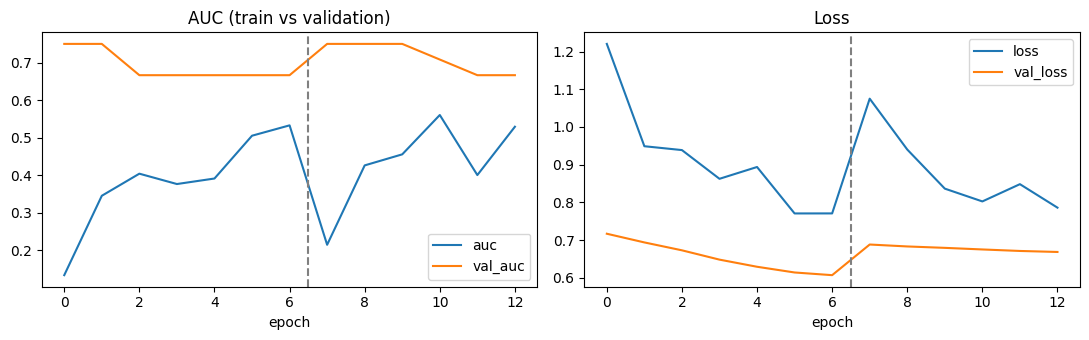

In [12]:
base.trainable = True
for l in base.layers[:-N_UNFREEZE]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False          # on garde les BatchNorm figées (petit dataset)
compile_model(model, 1e-5)
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=25, class_weight=CLASS_WEIGHT, callbacks=[es()], verbose=2)

hist = {k: h1.history[k] + h2.history[k] for k in ["auc", "val_auc", "loss", "val_loss"]}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for k in ["auc", "val_auc"]: ax[0].plot(hist[k], label=k)
for k in ["loss", "val_loss"]: ax[1].plot(hist[k], label=k)
for a in ax: a.axvline(len(h1.history["auc"]) - 0.5, ls="--", c="gray"); a.legend(); a.set_xlabel("epoch")
ax[0].set_title("AUC (train vs validation)"); ax[1].set_title("Loss"); plt.tight_layout()
plt.savefig(f"{OUT}/training_curves.png", dpi=120); plt.show()

## 8. Seuil de décision — choisi sur la VALIDATION uniquement
Le seuil est fixé ici (indice de Youden) **avant** de regarder le test, puis il n'est plus modifié.

In [13]:
p_va = model.predict(ds_va, verbose=0).ravel()
print("Validation AUC:", roc_auc_score(val.y, p_va))
fpr, tpr, thr = roc_curve(val.y, p_va)
THR = float(thr[np.argmax(tpr - fpr)])
if not np.isfinite(THR) or THR > 1:
    THR = 0.5
print("Threshold fixed on validation:", THR)
json.dump({"threshold": THR, "chosen_on": "validation (Youden J)"}, open(f"{OUT}/threshold.json", "w"))

Validation AUC: 0.7500000000000001
Threshold fixed on validation: 0.25149619579315186


## 9. ÉVALUATION FINALE SUR LE TEST — à exécuter une seule fois
⚠️ Ne modifie plus rien (modèle, seuil, données) après avoir vu ces chiffres. Si tu changes quelque chose, il faudra le dire dans le rapport.

In [14]:
def trunc(x, d=3):
    # Tronque (n'arrondit jamais vers le haut)
    return "n/a" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{math.floor(x * 10**d) / 10**d:.{d}f}"

def boot_auc_ci(y, p, B=2000):
    y, p, rng, s = np.asarray(y), np.asarray(p), np.random.default_rng(SEED), []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) == 2:
            s.append(roc_auc_score(y[i], p[i]))
    return (np.percentile(s, 2.5), np.percentile(s, 97.5)) if s else (float("nan"), float("nan"))

def block(name, y, p, thr):
    y, p = np.asarray(y), np.asarray(p)
    tn, fp, fn, tp = confusion_matrix(y, (p >= thr).astype(int), labels=[0, 1]).ravel()
    both = len(set(y)) == 2
    auc = roc_auc_score(y, p) if both else float("nan")
    lo, hi = boot_auc_ci(y, p) if both else (float("nan"), float("nan"))
    sens = tp / (tp + fn) if tp + fn else float("nan")
    spec = tn / (tn + fp) if tn + fp else float("nan")
    return {"group": name, "n": len(y), "n_AN": int(y.sum()), "n_other": int((1 - y).sum()),
            "AUC": trunc(auc), "AUC_95CI": f"{trunc(lo)}-{trunc(hi)}" if both else "n/a",
            "Sensitivity": f"{trunc(sens)} ({tp}/{tp+fn})", "Specificity": f"{trunc(spec)} ({tn}/{tn+fp})",
            "TP": int(tp), "FN": int(fn), "TN": int(tn), "FP": int(fp)}

p_te = model.predict(ds_te, verbose=0).ravel()
test = test.copy(); test["p"] = p_te; test["pred"] = (p_te >= THR).astype(int)

rows = [block("ALL (test)", test.y, test.p, THR)]
for g in ["I-II", "III-IV", "V-VI", "unknown"]:
    t = test[test.tone == g]
    if len(t):
        rows.append(block(f"Fitzpatrick {g}" if g != "unknown" else "Tone unknown", t.y, t.p, THR))
if test.source.nunique() > 1:
    for src in sorted(test.source.unique()):
        t = test[test.source == src]
        rows.append(block(f"Source {src}", t.y, t.p, THR))
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/results_table.csv", index=False)
pd.set_option("display.width", 200); print(results.to_string(index=False))

             group  n  n_AN  n_other   AUC    AUC_95CI Sensitivity Specificity  TP  FN  TN  FP
        ALL (test)  8     4        4 0.437 0.000-1.000 0.750 (3/4) 0.250 (1/4)   3   1   1   3
Fitzpatrick III-IV  8     4        4 0.437 0.000-1.000 0.750 (3/4) 0.250 (1/4)   3   1   1   3


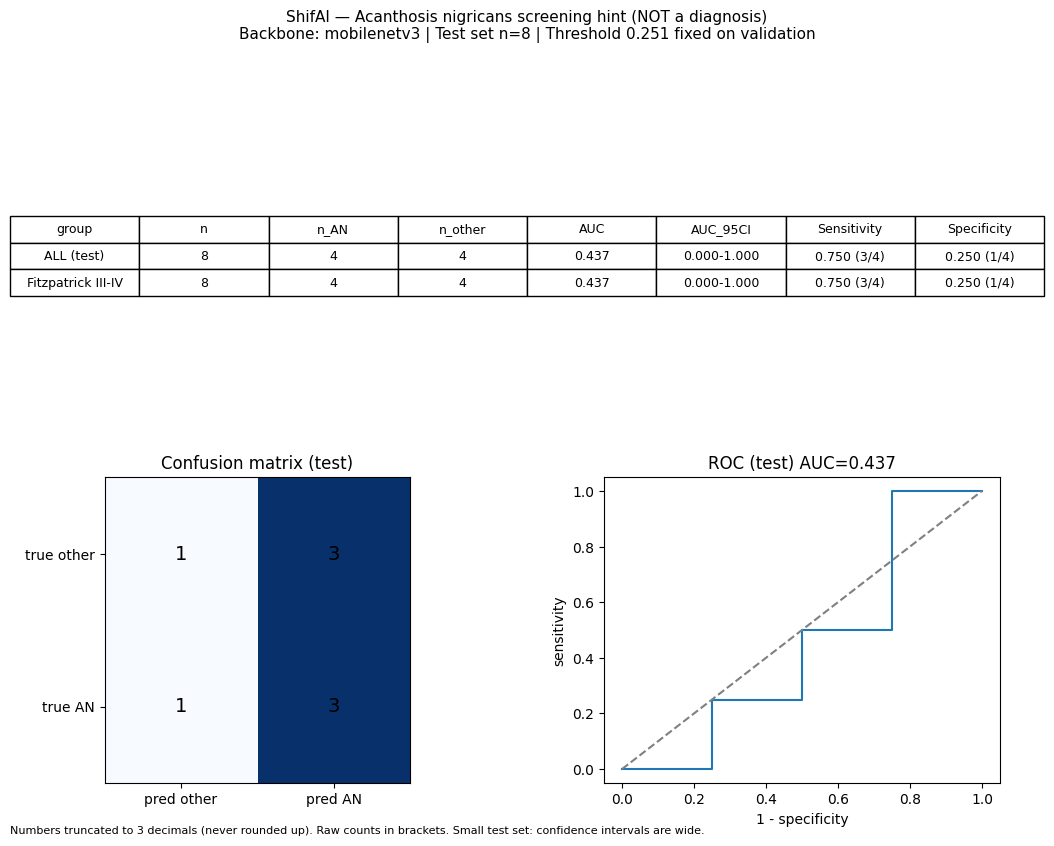

In [15]:
cm = confusion_matrix(test.y, test.pred, labels=[0, 1])
fpr_t, tpr_t, _ = roc_curve(test.y, test.p)
fig = plt.figure(figsize=(11, 8.5))
fig.suptitle(f"ShifAI — Acanthosis nigricans screening hint (NOT a diagnosis)\n"
             f"Backbone: {BACKBONE} | Test set n={len(test)} | Threshold {THR:.3f} fixed on validation", fontsize=11)
ax = fig.add_axes([0.03, 0.50, 0.94, 0.38]); ax.axis("off")
cols = ["group", "n", "n_AN", "n_other", "AUC", "AUC_95CI", "Sensitivity", "Specificity"]
tb = ax.table(cellText=results[cols].values, colLabels=cols, loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(9); tb.scale(1, 1.6)
a1 = fig.add_axes([0.08, 0.07, 0.35, 0.36])
a1.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): a1.text(j, i, v, ha="center", va="center", fontsize=14)
a1.set_xticks([0, 1], ["pred other", "pred AN"]); a1.set_yticks([0, 1], ["true other", "true AN"])
a1.set_title("Confusion matrix (test)")
a2 = fig.add_axes([0.57, 0.07, 0.36, 0.36])
a2.plot(fpr_t, tpr_t); a2.plot([0, 1], [0, 1], "--", c="gray")
a2.set_xlabel("1 - specificity"); a2.set_ylabel("sensitivity"); a2.set_title(f"ROC (test) AUC={rows[0]['AUC']}")
fig.text(0.03, 0.01, "Numbers truncated to 3 decimals (never rounded up). Raw counts in brackets. "
         "Small test set: confidence intervals are wide.", fontsize=8)
plt.savefig(f"{OUT}/results_page.png", dpi=150); plt.savefig(f"{OUT}/results_page.pdf"); plt.show()

with open(f"{OUT}/results_table.md", "w") as f:
    f.write(f"# Acanthosis nigricans model — test results\n\nScreening hint only, not a diagnosis. Backbone: {BACKBONE}. "
            f"Threshold {THR:.3f} chosen on validation.\n\n")
    try:
        f.write(results[cols + ["TP", "FN", "TN", "FP"]].to_markdown(index=False))
    except ImportError:
        f.write(results.to_string(index=False))

## 10. Grad-CAM et 4 exemples (2 justes, 2 faux)

2 right + 2 wrong examples available


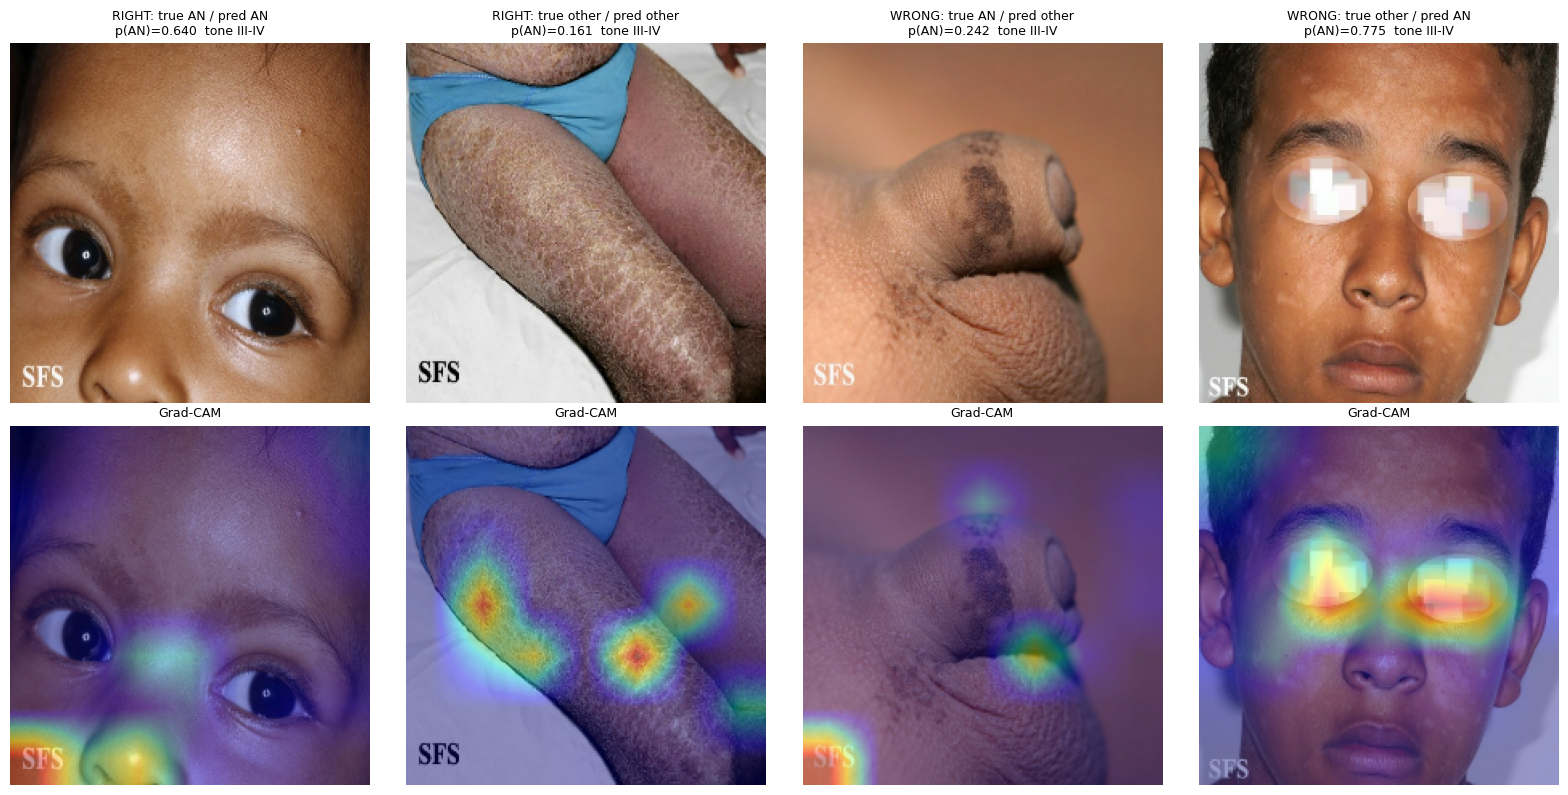

In [16]:
gap_l, drop_l, pred_l = model.get_layer("gap"), model.get_layer("drop"), model.get_layer("pred")

def gradcam(img):
    x = tf.convert_to_tensor(img[None])
    with tf.GradientTape() as tape:
        conv = base(x, training=False)
        tape.watch(conv)
        out = pred_l(drop_l(gap_l(conv), training=False))
    g = tape.gradient(out, conv)[0]
    w = tf.reduce_mean(g, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * w, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG, IMG)).numpy()[..., 0]
    return cam, float(out[0, 0])

def pick(df_, n):
    return df_.iloc[:n]

t = test.copy()
t["conf"] = np.abs(t.p - THR)
right = pd.concat([pick(t[(t.y == 1) & (t.pred == 1)].sort_values("conf", ascending=False), 1),
                   pick(t[(t.y == 0) & (t.pred == 0)].sort_values("conf", ascending=False), 1)])
wrong = pd.concat([pick(t[(t.y == 1) & (t.pred == 0)].sort_values("conf", ascending=False), 1),
                   pick(t[(t.y == 0) & (t.pred == 1)].sort_values("conf", ascending=False), 1)])
if len(right) < 2: right = pd.concat([right, t[(t.y == t.pred) & ~t.index.isin(right.index)].head(2 - len(right))])
if len(wrong) < 2: wrong = pd.concat([wrong, t[(t.y != t.pred) & ~t.index.isin(wrong.index)].head(2 - len(wrong))])
examples = pd.concat([right.assign(kind="RIGHT"), wrong.assign(kind="WRONG")])
print(f"{len(right)} right + {len(wrong)} wrong examples available")

fig, axs = plt.subplots(2, len(examples), figsize=(4 * len(examples), 8))
axs = np.array(axs).reshape(2, -1)
for k, (_, r) in enumerate(examples.iterrows()):
    img, _ = load(r.path, r.y); img = img.numpy()
    cam, prob = gradcam(img)
    title = (f"{r.kind}: true {'AN' if r.y else 'other'} / pred {'AN' if r.pred else 'other'}\n"
             f"p(AN)={trunc(prob)}  tone {r.tone}")
    axs[0, k].imshow(img.astype("uint8")); axs[0, k].set_title(title, fontsize=9); axs[0, k].axis("off")
    axs[1, k].imshow(img.astype("uint8")); axs[1, k].imshow(cam, cmap="jet", alpha=0.4)
    axs[1, k].set_title("Grad-CAM", fontsize=9); axs[1, k].axis("off")
    plt.imsave(f"{OUT}/example_{k+1}_{r.kind.lower()}.png", img.astype("uint8"))
plt.tight_layout(); plt.savefig(f"{OUT}/examples_gradcam.png", dpi=130); plt.show()

## 11. Export TFLite (float16) + vérification

In [17]:
exp_dir = f"{WORK}/saved_model"
try:
    model.export(exp_dir)
    converter = tf.lite.TFLiteConverter.from_saved_model(exp_dir)
except Exception as e:
    print("model.export failed, using from_keras_model:", e)
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tfl = converter.convert()
open(f"{OUT}/model.tflite", "wb").write(tfl)
size_mb = os.path.getsize(f"{OUT}/model.tflite") / 1e6
print(f"model.tflite size: {size_mb:.2f} MB")

interp = tf.lite.Interpreter(model_path=f"{OUT}/model.tflite"); interp.allocate_tensors()
i_d, o_d = interp.get_input_details()[0], interp.get_output_details()[0]
diffs = []
for path, pk in zip(test.path.values[:20], test.p.values[:20]):
    img, _ = load(path, 0)
    interp.set_tensor(i_d["index"], img.numpy()[None].astype(i_d["dtype"]))
    interp.invoke(); diffs.append(abs(float(interp.get_tensor(o_d["index"])[0, 0]) - pk))
print("Max |TFLite - Keras| on 20 test images:", max(diffs))

info = {"file": "model.tflite", "size_MB": round(size_mb, 2), "backbone": BACKBONE,
        "input": f"float32 [1,{IMG},{IMG},3], RGB, raw pixel values 0-255 (NO normalisation, it is inside the model)",
        "output": "float32 [1,1] = probability of acanthosis-nigricans-like appearance (sigmoid)",
        "threshold": THR, "threshold_chosen_on": "validation set",
        "wording_in_app": "Screening hint only, not a diagnosis. If positive: 'Signs that may be worth showing to a doctor.'"}
json.dump(info, open(f"{OUT}/model_info.json", "w"), indent=2); print(json.dumps(info, indent=2))

INFO:tensorflow:Assets written to: /kaggle/working/an_work/saved_model/assets


INFO:tensorflow:Assets written to: /kaggle/working/an_work/saved_model/assets


Saved artifact at '/kaggle/working/an_work/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_5')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  137463889255440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137463889255824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137463889259664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137463887709968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137463889255632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137463889258320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137463889260240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137463889260048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137463889251024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137463889263888: TensorSpec(shape=(), dtype=tf.resource, name=N

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## 12. Limites (texte généré avec les vrais chiffres) et aide à la décision pour lundi

In [18]:
r0 = rows[0]
tone_lines = "; ".join(f"{r['group']}: n_AN={r['n_AN']}, AUC={r['AUC']}, sensitivity={r['Sensitivity']}" for r in rows[1:] if r['group'].startswith("Fitzpatrick"))
photo_note = ("Images are clinical/atlas photos, not smartphone photos of the neck: real-world accuracy in the app is likely lower."
              if "SCIN" not in set(data.source) else
              f"Part of the data are smartphone photos (SCIN: {int(((test.source=='SCIN')&(test.y==1)).sum())} AN test images), but not specifically of the neck, so real-world accuracy in the app may still be lower.")
missing = [f"Fitzpatrick {g}" for g in ["I-II", "III-IV", "V-VI"]
           if ((test.tone == g) & (test.y == 1)).sum() == 0]
limits = f"""LIMITS. This model is a screening hint, not a diagnosis, and must never be presented as one. \
It was trained on a very small dataset: {int((data.y==1).sum())} acanthosis nigricans images in total \
(train/val/test = {int((train.y==1).sum())}/{int((val.y==1).sum())}/{int((test.y==1).sum())}), from: {', '.join(sorted(data.source.unique()))} \
(see dataset_sources.csv for licences). The test set has only {r0['n']} images, so the test AUC of {r0['AUC']} \
(95% bootstrap CI {r0['AUC_95CI']}) is uncertain. By skin tone: {tone_lines}. \
{('No acanthosis nigricans test images in: ' + ', '.join(missing) + ', so performance there is unknown. ') if missing else ''}\
Each skin-tone subgroup contains only a handful of positive images, so these subgroup numbers are indicative at best; \
performance on darker skin, which matters for a Moroccan audience, is not established. \
The negative class contains other skin diseases only, no photos of normal skin. \
{photo_note} \
Before any real use, the model needs a larger, consented, tone-balanced dataset collected with phones, and clinical validation."""
open(f"{OUT}/limits.txt", "w").write(limits); print(limits)

try:
    lo = float(r0["AUC_95CI"].split("-")[0])
except Exception:
    lo = float("nan")
print("\n--- Suggested demo decision (team's final call) ---")
if lo >= 0.70 and not missing:
    print("Numbers look reasonable: can be demoed as a SCREENING HINT, with the limits stated on screen.")
else:
    print("Results too uncertain: show the notebook as an EXPERIMENT, not a live feature.")

LIMITS. This model is a screening hint, not a diagnosis, and must never be presented as one. It was trained on a very small dataset: 24 acanthosis nigricans images in total (train/val/test = 16/4/4), from: Fitzpatrick17k, SCIN (see dataset_sources.csv for licences). The test set has only 8 images, so the test AUC of 0.437 (95% bootstrap CI 0.000-1.000) is uncertain. By skin tone: Fitzpatrick III-IV: n_AN=4, AUC=0.437, sensitivity=0.750 (3/4). No acanthosis nigricans test images in: Fitzpatrick I-II, Fitzpatrick V-VI, so performance there is unknown. Each skin-tone subgroup contains only a handful of positive images, so these subgroup numbers are indicative at best; performance on darker skin, which matters for a Moroccan audience, is not established. The negative class contains other skin diseases only, no photos of normal skin. Part of the data are smartphone photos (SCIN: 0 AN test images), but not specifically of the neck, so real-world accuracy in the app may still be lower. Before

## 13. Télécharger tous les livrables

In [19]:
zip_path = f"{ROOT}/shifai_an_outputs.zip"
with zipfile.ZipFile(zip_path, "w") as z:
    for f in sorted(os.listdir(OUT)):
        z.write(f"{OUT}/{f}", f)
print(sorted(os.listdir(OUT)))
if ON_KAGGLE:
    print("Kaggle : le zip est dans l'onglet Output (à droite) ->", zip_path)
else:
    from google.colab import files
    files.download(zip_path)

['dataset_sources.csv', 'example_1_right.png', 'example_2_right.png', 'example_3_wrong.png', 'example_4_wrong.png', 'examples_gradcam.png', 'limits.txt', 'model.tflite', 'model_info.json', 'results_page.pdf', 'results_page.png', 'results_table.csv', 'results_table.md', 'splits.csv', 'threshold.json', 'training_curves.png']
Kaggle : le zip est dans l'onglet Output (à droite) -> /kaggle/working/shifai_an_outputs.zip


**Ensuite :** `Fichier → Télécharger → Télécharger le fichier .ipynb` pour envoyer le notebook avec tous les résultats visibles.

À envoyer à l'équipe : ce notebook (.ipynb), `results_page.pdf` (tableau sur une page), `examples_gradcam.png` + `example_1..4_*.png`, `model.tflite` (+ `model_info.json`), `limits.txt`, `dataset_sources.csv`.